# ARX + TP Model — OSPulse ECoG

**One-time setup:** `pip install ipympl` (for the interactive bad-channel picker).

| Section | Run once? | Notes |
|---|---|---|
| Imports | once | |
| Parameters | once | edit here, then re-run load |
| 1 — Load session | once | all 96 ch, no bad-ch removal yet |
| 1b — Bad channel picker | once | click to mark, Done to confirm |
| 1c — Apply + save | once | drops bad ch from session, saves pkl |
| 1d — Bandpass filter | re-run to change band | modifies `conditions` in-place |
| 2 — Stim inputs | once after load | |
| 2b — Spatial grid | re-run freely | shows filtered, good-ch data |
| 3 — ARX fit | re-run to change conditions | |
| 4 — TP decomposition | re-run to change hull/tol | |
| 5/6 — Plots | re-run freely | |

In [32]:
from __future__ import annotations
from pathlib import Path
import sys

import matplotlib.pyplot as plt
import numpy as np

%matplotlib inline

PROJECT_ROOT = Path().resolve().parents[1]   # tp_python/examples/ → project root
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

from tp_python.utils.ospulse_loader import load_ospulse_session, FS_RAW
from tp_python.tptoolbox.model import ConvexTPStructure

print(f"Project root: {PROJECT_ROOT}")

Project root: C:\Users\aditya\Documents\projects\TPModel


## Parameters
Edit here, then re-run from **cell 3 (Load session)** if you change `monkey/date/site/ds_factor`.  
For fitting/TP params only, re-run from **cell 5** onward.

In [33]:
monkey    = "Jalapeno"
date      = "091114"
site      = "M1"
base_path = r"Z:\Yazdan Lab Members\Grad\brianam2\ParameterStudy\Data"

electrode_pos_file = r"Z:\Yazdan Lab Members\Grad\fschwock\8 Reach\electrode_positions.pkl"

ds_factor  = 3        # decimation; fs = FS_RAW / ds_factor ≈ 1017 Hz
train_frac = 0.80

# Stim protocol timing (seconds)
PRE_S  = 1.0
STIM_S = 5.0

pw_unit_scale = 1.0   # 1.0 = seconds, 1e-3 = ms, 1e-6 = µs

hull_types = ["snnn"]
hosvd_tol  = 1e-4

# Bandpass filter band (used in section 1d)
# choices: delta / theta / alpha / beta / low_gamma / gamma / broadband
BAND = "broadband"

# Set True in the apply cell (1c) to write bad channels to pkl
SAVE_TO_PKL = False

## 1 — Load session  *(run once)*

Loads all 96 channels (`bad_ch_file=None`). Bad channel removal happens in section 1c.

In [34]:
print(f"Loading {monkey} {date} {site} ...")

session = load_ospulse_session(
    monkey          = monkey,
    date            = date,
    site            = site,
    base_path       = base_path,
    sep_stim_params = "1",
    bad_ch_file     = None,   # all 96 ch; bad-ch removal done in section 1c
    ds_factor       = ds_factor,
    remove_dc       = True,
    verbose         = True,
)

fs           = session["fs"]
n_conditions = session["n_conditions"]
n_trials     = session["n_trials"]
n_channels   = session["n_channels"]
n_samples    = session["n_samples"]
conditions   = session["conditions"]

print(f"\nfs={fs:.2f} Hz   n_conditions={n_conditions}   "
      f"n_trials={n_trials}   n_channels={n_channels}   n_samples={n_samples}")

Loading Jalapeno 091114 M1 ...
  loaded ch 96/96
Session: Jalapeno 091114 M1
  raw channels : 96
  bad channels : 0  []
  good channels: 96
  ecog shape   : (12, 60, 96, 7121)  (cond × trials × ch × samples)
  fs           : 1017.25 Hz
  stim conditions:
    [ 0]     0.1 Hz  1000000.0000
    [ 1]    10.0 Hz  1000.0000
    [ 2]    20.0 Hz  1000.0000
    [ 3]    30.0 Hz  1000.0000
    [ 4]    35.0 Hz  1000.0000
    [ 5]    40.0 Hz  1000.0000
    [ 6]    50.0 Hz  1000.0000
    [ 7]    70.0 Hz  1000.0000
    [ 8]   100.0 Hz  1000.0000
    [ 9]   150.0 Hz  1000.0000
    [10]    10.0 Hz  500.0000
    [11]    10.0 Hz  5000.0000

fs=1017.25 Hz   n_conditions=12   n_trials=60   n_channels=96   n_samples=7121


## 1b — Bad channel picker  *(run once)*

Plots all 96 electrodes at physical positions with the condition-0 trial average.  
**Click** an electrode to toggle bad (red) / good (blue).  
Press **Done** or **Enter** when finished, then run section 1c.

In [35]:
%matplotlib widget
# requires: pip install ipympl  — restart kernel after installing

import pickle
from matplotlib.widgets import Button

# ── electrode positions ───────────────────────────────────────────────────────
with open(electrode_pos_file, "rb") as _f:
    _ep_raw = pickle.load(_f)

elec_pos = {int(k): (float(np.asarray(v).ravel()[0]),
                     float(np.asarray(v).ravel()[1]))
            for k, v in _ep_raw.items()}

# ── trial average, condition 0, all 96 channels ───────────────────────────────
_cond0      = session["conditions"][0]
mean_trace  = _cond0["mean"]                    # (96, n_samples)
t_axis      = np.arange(mean_trace.shape[1]) / fs

valid_channels = sorted(ch for ch in elec_pos if 0 <= ch < mean_trace.shape[0])
positions      = np.array([elec_pos[ch] for ch in valid_channels])

# ── spatial scaling ───────────────────────────────────────────────────────────
def _picker_med_sp(vals):
    u = np.unique(np.round(vals, 6))
    if u.size < 2: return 1.0
    d = np.diff(u); d = d[d > 0]
    return float(np.median(d)) if d.size else 1.0

x_spacing    = _picker_med_sp(positions[:, 0])
y_spacing    = _picker_med_sp(positions[:, 1])
click_tol    = 0.6  * min(x_spacing, y_spacing)
trace_half_w = 0.5  * 0.80 * x_spacing
trace_half_h = 0.5  * 0.35 * y_spacing

t_norm    = (t_axis - t_axis.min()) / (t_axis.max() - t_axis.min())
t_norm    = t_norm * 2 * trace_half_w - trace_half_w
amp_scale = float(np.nanpercentile(np.abs(mean_trace[valid_channels]), 99)) or 1.0

# ── state (read by section 1c) ────────────────────────────────────────────────
bad_set = set()

COLOR_GOOD = "#4fc3f7"
COLOR_BAD  = "#ef5350"

# ── figure ────────────────────────────────────────────────────────────────────
fig_picker, ax_picker = plt.subplots(figsize=(13, 10))
fig_picker.patch.set_facecolor("#1a1a2e")
ax_picker.set_facecolor("#1a1a2e")
plt.subplots_adjust(bottom=0.08)

trace_lines, dot_markers, label_texts = {}, {}, {}

for ch in valid_channels:
    x0, y0 = elec_pos[ch]
    x_tr   = x0 + t_norm
    y_tr   = y0 + (mean_trace[ch] / amp_scale) * trace_half_h

    trace_lines[ch], = ax_picker.plot(x_tr, y_tr,
                                      color=COLOR_GOOD, lw=0.9, alpha=0.85,
                                      picker=False)
    dot_markers[ch], = ax_picker.plot([x0], [y0], "o",
                                      color=COLOR_GOOD, ms=5, zorder=4,
                                      picker=False)
    label_texts[ch]  = ax_picker.text(x0, y0 - 0.42 * y_spacing, str(ch),
                                      ha="center", va="top", fontsize=6,
                                      color=COLOR_GOOD, zorder=5)

status_text = fig_picker.text(0.5, 0.01, "Bad channels: none",
                              ha="center", va="bottom", fontsize=9,
                              color=COLOR_BAD, transform=fig_picker.transFigure)

ax_picker.set_aspect("equal", adjustable="datalim")
ax_picker.set_xlabel("Electrode X (mm)", color="white", fontsize=9)
ax_picker.set_ylabel("Electrode Y (mm)", color="white", fontsize=9)
ax_picker.tick_params(colors="white")
for sp in ax_picker.spines.values():
    sp.set_edgecolor("#444")
ax_picker.set_title(
    f"{monkey}  {date}  {site}  |  cond 0  {_cond0['stim_freq']:.1f} Hz  "
    f"pw={_cond0['stim_pw']:.4f}\n"
    "Click electrode to toggle bad  |  Done or Enter when finished",
    fontsize=10, color="white", pad=10,
)
ax_picker.grid(True, alpha=0.12, color="white")

_ax_btn = fig_picker.add_axes([0.44, 0.02, 0.12, 0.04])
_btn    = Button(_ax_btn, "Done", color="#2a2a4a", hovercolor="#3a3a6a")
_btn.label.set_color("white")

# ── callbacks ─────────────────────────────────────────────────────────────────
def _update_ch(ch):
    c = COLOR_BAD if ch in bad_set else COLOR_GOOD
    trace_lines[ch].set(color=c, linewidth=1.5 if ch in bad_set else 0.9)
    dot_markers[ch].set(color=c, markersize=7  if ch in bad_set else 5)
    label_texts[ch].set_color(c)

def _refresh_status():
    bl = sorted(bad_set)
    status_text.set_text(
        f"Bad channels (0-idx): {bl}" if bl else "Bad channels: none"
    )
    fig_picker.canvas.draw_idle()

def _on_click(event):
    if event.inaxes is not ax_picker or event.xdata is None:
        return
    dists   = np.linalg.norm(positions - [event.xdata, event.ydata], axis=1)
    nearest = int(np.argmin(dists))
    if dists[nearest] > click_tol:
        return
    ch = valid_channels[nearest]
    bad_set.discard(ch) if ch in bad_set else bad_set.add(ch)
    _update_ch(ch)
    _refresh_status()

def _on_done(_=None):
    print(f"Bad channels (0-indexed): {sorted(bad_set)}")
    print("Run section 1c to apply.")

def _on_key(event):
    if event.key in ("enter", "q"):
        _on_done()

fig_picker.canvas.mpl_connect("button_press_event", _on_click)
fig_picker.canvas.mpl_connect("key_press_event",    _on_key)
_btn.on_clicked(_on_done)
plt.tight_layout(rect=[0, 0.06, 1, 1])
plt.show()

RuntimeError: 'widget' is not a recognised GUI loop or backend name

## 1c — Apply bad channels + save  *(run once after picker)*

Drops the channels marked in `bad_set` from the session in-place.  
Set `SAVE_TO_PKL = True` in Parameters to persist to file.

In [ ]:
import pickle

SAVE_TO_PKL = False   # ← set True to write pkl

# read from picker, or fall back to existing pkl, or empty
if 'bad_set' in dir() and bad_set is not None:
    final_bad = sorted(bad_set)
else:
    _pkl_path = PROJECT_ROOT / "tp_python" / "bad_channels" / f"{monkey}_{date}.pkl"
    if _pkl_path.exists():
        with open(_pkl_path, "rb") as _f:
            _ex = pickle.load(_f)
        final_bad = sorted(ch - 1 for ch in _ex.get(site, []))
        print(f"Loaded from pkl: {final_bad} (0-indexed)")
    else:
        final_bad = []
        print("No picker run and no pkl — no channels removed.")

# ── Drop from session in-place ────────────────────────────────────────────────
_n_ch_raw = session["ecog"].shape[2]
_good     = [ch for ch in range(_n_ch_raw) if ch not in set(final_bad)]

session["ecog"]          = session["ecog"][:, :, _good, :]
session["mean"]          = session["mean"][:, _good, :]
session["bad_channels"]  = final_bad
session["good_channels"] = _good
session["n_channels"]    = len(_good)

for _cond in session["conditions"]:
    _cond["ecog"] = _cond["ecog"][:, _good, :]
    _cond["mean"] = _cond["mean"][_good, :]

n_channels = session["n_channels"]
conditions = session["conditions"]
print(f"Bad channels (0-indexed): {final_bad}")
print(f"Kept {n_channels} / {_n_ch_raw} channels.")

# ── Save to pkl ───────────────────────────────────────────────────────────────
if SAVE_TO_PKL:
    _pkl_path = PROJECT_ROOT / "tp_python" / "bad_channels" / f"{monkey}_{date}.pkl"
    _pkl_path.parent.mkdir(parents=True, exist_ok=True)
    _existing: dict = {}
    if _pkl_path.exists():
        with open(_pkl_path, "rb") as _f:
            _existing = pickle.load(_f)
    _existing[site] = sorted(ch + 1 for ch in final_bad)   # 1-indexed
    with open(_pkl_path, "wb") as _f:
        pickle.dump(_existing, _f)
    print(f"Saved → {_pkl_path}  ({site}: {_existing[site]}  1-indexed)")

## 1d — Bandpass filter  *(re-run to change band)*

Filters `conditions[c]["ecog"]` in-place with a 4th-order Butterworth bandpass.  
Change `BAND` in Parameters and re-run this cell; reload from section 1 to go back to broadband.

In [ ]:
from scipy.signal import butter, sosfiltfilt

BANDS = {
    "delta":     (0.5,   4.0),
    "theta":     (4.0,   8.0),
    "alpha":     (8.0,  13.0),
    "beta":     (13.0,  30.0),
    "low_gamma":(30.0,  60.0),
    "gamma":    (60.0, 120.0),
    "broadband": (1.0, 200.0),
}

fmin, fmax = BANDS[BAND]
fmax = min(fmax, fs / 2.0 * 0.95)   # stay below Nyquist

sos = butter(4, [fmin, fmax], btype="bandpass", fs=fs, output="sos")

for _cond in session["conditions"]:
    _ecog = sosfiltfilt(sos, _cond["ecog"].astype(np.float64), axis=-1).astype(np.float32)
    _cond["ecog"] = _ecog
    _cond["mean"] = _ecog.mean(axis=0)

session["ecog"] = np.stack([c["ecog"] for c in session["conditions"]])
session["mean"] = np.stack([c["mean"] for c in session["conditions"]])

print(f"Bandpass filtered: {BAND}  [{fmin:.1f}, {fmax:.1f}] Hz  (4th-order Butterworth)")

## 2 — Stim inputs & train/test split  *(run once after 1c + 1d)*

In [ ]:
def make_stim_input(n_samples, fs, stim_freq, stim_pw):
    u = np.zeros(n_samples, dtype=np.float32)
    pre_n  = int(round(PRE_S * fs))
    stim_n = min(int(round(STIM_S * fs)), n_samples - pre_n)
    if stim_freq <= 0 or stim_pw <= 0 or stim_n <= 0:
        return u
    period_n = int(round(fs / stim_freq))
    pw_n     = max(1, int(round(stim_pw * fs)))
    for onset in range(0, stim_n, period_n):
        off = min(onset + pw_n, stim_n)
        u[pre_n + onset : pre_n + off] = 1.0
    return u

inputs = []
for c, cond in enumerate(conditions):
    freq = cond["stim_freq"]
    pw   = cond["stim_pw"] * pw_unit_scale
    u_template = make_stim_input(n_samples, fs, freq, pw)
    inputs.append(np.tile(u_template, (n_trials, 1)))
    print(f"  cond {c:2d}: freq={freq:.2f} Hz  pw={pw:.4f} s  "
          f"pulse_samples={int(round(pw*fs))}  "
          f"stim_on_fraction={u_template.mean():.3f}")

n_train   = int(train_frac * n_trials)
n_test    = n_trials - n_train
train_idx = np.arange(n_train)
test_idx  = np.arange(n_train, n_trials)
print(f"\nTrain trials: {n_train}   Test trials: {n_test}")

  cond  0: freq=0.10 Hz  pw=1000000.0000 s  pulse_samples=1017253333  stim_on_fraction=0.714
  cond  1: freq=10.00 Hz  pw=1000.0000 s  pulse_samples=1017253  stim_on_fraction=0.714
  cond  2: freq=20.00 Hz  pw=1000.0000 s  pulse_samples=1017253  stim_on_fraction=0.714
  cond  3: freq=30.00 Hz  pw=1000.0000 s  pulse_samples=1017253  stim_on_fraction=0.714
  cond  4: freq=35.00 Hz  pw=1000.0000 s  pulse_samples=1017253  stim_on_fraction=0.714
  cond  5: freq=40.00 Hz  pw=1000.0000 s  pulse_samples=1017253  stim_on_fraction=0.714
  cond  6: freq=50.00 Hz  pw=1000.0000 s  pulse_samples=1017253  stim_on_fraction=0.714
  cond  7: freq=70.00 Hz  pw=1000.0000 s  pulse_samples=1017253  stim_on_fraction=0.714
  cond  8: freq=100.00 Hz  pw=1000.0000 s  pulse_samples=1017253  stim_on_fraction=0.714
  cond  9: freq=150.00 Hz  pw=1000.0000 s  pulse_samples=1017253  stim_on_fraction=0.714
  cond 10: freq=10.00 Hz  pw=500.0000 s  pulse_samples=508627  stim_on_fraction=0.714
  cond 11: freq=10.00 Hz  p

Saved → C:\Users\aditya\Documents\projects\TPModel\tp_python\plots\spatial_avg_Jalapeno_091114_M1_conds0.png


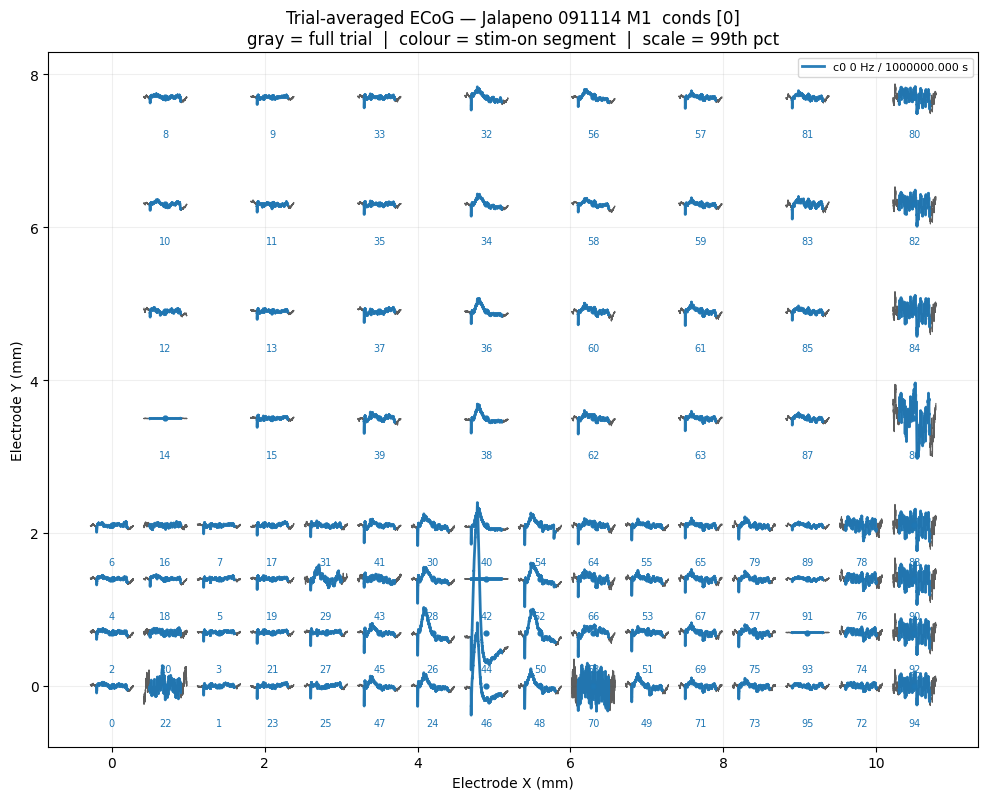

In [ ]:
import pickle

PLOT_CONDITIONS    = FIT_CONDITIONS if 'FIT_CONDITIONS' in dir() else list(range(n_conditions))
electrode_pos_file = r"Z:\Yazdan Lab Members\Grad\fschwock\8 Reach\electrode_positions.pkl"

# ── Load electrode positions (0-indexed key → (x, y)) ────────────────────────
with open(electrode_pos_file, "rb") as _f:
    _raw_pos = pickle.load(_f)

_elec_pos = {
    int(k): (float(np.asarray(v).ravel()[0]), float(np.asarray(v).ravel()[1]))
    for k, v in _raw_pos.items()
}

# ── Map original channel numbers → index in the (bad-ch-removed) data ─────────
_good_to_idx = {ch: i for i, ch in enumerate(session["good_channels"])}

# valid = has a position AND was not removed as bad
_valid_ch  = sorted(ch for ch in _elec_pos if ch in _good_to_idx)
_positions = np.array([_elec_pos[ch] for ch in _valid_ch])   # (N, 2)

# ── Spatial scaling (same as demo.ipynb) ─────────────────────────────────────
def _med_sp(vals):
    u = np.unique(np.round(vals, 6))
    if u.size < 2: return 1.0
    d = np.diff(u); d = d[d > 0]
    return float(np.median(d)) if d.size else 1.0

_x_sp = _med_sp(_positions[:, 0])
_y_sp = _med_sp(_positions[:, 1])
_tw   = 0.8  * _x_sp    # trace width  (fraction of electrode spacing)
_th   = 0.20 * _y_sp    # trace height

# ── Time normalisation: full trial mapped to [-0.5, 0.5] * _tw ───────────────
_t_s    = np.arange(n_samples) / fs
_t_norm = (_t_s - _t_s[0]) / (_t_s[-1] - _t_s[0]) - 0.5

# ── Global amplitude scale across all plotted conditions ─────────────────────
_all_means = np.stack([
    conditions[c]["mean"][[_good_to_idx[ch] for ch in _valid_ch], :]
    for c in PLOT_CONDITIONS
])
_amp_scale = float(np.nanpercentile(np.abs(_all_means), 99)) or 1.0

# ── Plot ──────────────────────────────────────────────────────────────────────
_cmap = plt.cm.tab10
fig, ax = plt.subplots(figsize=(12, 10))

for ci, c_idx in enumerate(PLOT_CONDITIONS):
    cond    = conditions[c_idx]
    mean_c  = cond["mean"]                 # (n_channels_kept, n_samples)
    color   = _cmap(ci % 10)
    _stim   = inputs[c_idx][0].astype(bool)   # stim-on mask for this condition

    for i, ch in enumerate(_valid_ch):
        x0, y0  = _positions[i]
        trace   = mean_c[_good_to_idx[ch]]
        x_tr    = x0 + _t_norm * _tw
        y_tr    = y0 + (trace / _amp_scale) * _th

        # full trace in gray (first condition only to avoid overdrawing identical background)
        if ci == 0:
            ax.plot(x_tr, y_tr, color="0.25", linewidth=0.8, alpha=0.85)

        # stim-on segment in condition colour
        if _stim.any():
            _lbl = (f"c{c_idx} {cond['stim_freq']:.0f} Hz / "
                    f"{cond['stim_pw']*pw_unit_scale:.3f} s") if i == 0 else None
            ax.plot(x_tr[_stim], y_tr[_stim],
                    color=color, linewidth=2.0, alpha=0.95, label=_lbl)

# ── Electrode markers and labels (drawn once, on top) ────────────────────────
for i, ch in enumerate(_valid_ch):
    x0, y0 = _positions[i]
    ax.scatter(x0, y0, s=12, color="tab:blue", zorder=4)
    ax.text(x0, y0 - 0.30 * _y_sp, str(ch),
            ha="center", va="top", fontsize=7, color="tab:blue")

ax.set_aspect("equal", adjustable="box")
ax.set_xlabel("Electrode X (mm)")
ax.set_ylabel("Electrode Y (mm)")
ax.set_title(
    f"Trial-averaged ECoG — {monkey} {date} {site}  conds {PLOT_CONDITIONS}\n"
    f"gray = full trial  |  colour = stim-on segment  |  scale = 99th pct"
)
ax.grid(True, alpha=0.2)
ax.legend(fontsize=8, loc="upper right", framealpha=0.8)

_out_dir = PROJECT_ROOT / "tp_python" / "plots"
_out_dir.mkdir(parents=True, exist_ok=True)
_path = _out_dir / f"spatial_avg_{monkey}_{date}_{site}_conds{'_'.join(map(str,PLOT_CONDITIONS))}.png"
fig.savefig(_path, dpi=150, bbox_inches="tight")
print(f"Saved → {_path}")
plt.show()

## 3 — Fit ARX per condition

Change `FIT_CONDITIONS` and re-run this cell alone.  
Currently set to `[0]`; use `list(range(n_conditions))` for all 12.

In [ ]:
FIT_CONDITIONS = [0]   # ← change to list(range(n_conditions)) for all 12

arx_results: dict[int, dict] = {}

for c in FIT_CONDITIONS:
    cond    = conditions[c]
    ecog_c  = cond["ecog"]    # (n_trials, n_channels, n_samples)
    input_c = inputs[c]       # (n_trials, n_samples)

    Y_prev_list, U_prev_list, Y_next_list = [], [], []
    for t in train_idx:
        y = ecog_c[t].T.astype(np.float64)          # (n_samples, n_channels)
        u = input_c[t, :, None].astype(np.float64)  # (n_samples, 1)
        Y_prev_list.append(y[:-1])
        U_prev_list.append(u[:-1])
        Y_next_list.append(y[1:])

    Y_prev = np.vstack(Y_prev_list)
    U_prev = np.vstack(U_prev_list)
    Y_next = np.vstack(Y_next_list)
    N = Y_prev.shape[0]

    Z = np.hstack([Y_prev, U_prev])
    print(f"[cond {c}] Solving ARX: Z {Z.shape} → Y_next {Y_next.shape}  "
          f"({n_train} trials × {n_samples-1} steps = {N} pairs)")

    M, _, _, _ = np.linalg.lstsq(Z, Y_next, rcond=None)

    A_c = M[:n_channels, :].T
    B_c = M[n_channels:, :].T

    fit_err  = np.sqrt(np.mean((Y_next - Z @ M) ** 2))
    spec_rad = np.max(np.abs(np.linalg.eigvals(A_c)))
    print(f"  RMS error={fit_err:.6f}   spectral radius={spec_rad:.4f}")

    arx_results[c] = {"A": A_c, "B": B_c, "fit_err": fit_err, "spec_rad": spec_rad}

# alias for the single-condition case
c_fit = FIT_CONDITIONS[0]
A = arx_results[c_fit]["A"]
B = arx_results[c_fit]["B"]

[cond 0] Solving ARX: Z (341760, 97) → Y_next (341760, 96)  (48 trials × 7120 steps = 341760 pairs)
  RMS error=0.000009   spectral radius=0.9996


## 4 — TP model decomposition

Change `hull_types` or `hosvd_tol` in the Parameters cell and re-run from here.

In [ ]:
out_dir = PROJECT_ROOT / "tp_python" / "plots"
out_dir.mkdir(parents=True, exist_ok=True)
tag = f"{monkey}_{date}_{site}_cond{c_fit}"

tp_results: dict[str, tuple] = {}   # ht -> (Sco, Uco, sv)

for ht in hull_types:
    print(f"\n--- Hull: {ht} ---")
    try:
        Sco, Uco, sv, _, _ = ConvexTPStructure(A, [ht, ht], tol=hosvd_tol)
        tp_results[ht] = (Sco, Uco, sv)
        print(f"  Core shape : {Sco.shape}")
        for dim_idx, (w, s) in enumerate(zip(Uco, sv)):
            if w is None:
                continue
            print(f"  dim {dim_idx+1} : {w.shape[1]} vertices  "
                  f"top-5 sv = {s[:5].round(4)}")
    except Exception as exc:
        print(f"  FAILED: {exc}")

if not tp_results:
    raise RuntimeError("All hull types failed.")


--- Hull: snnn ---
  Core shape : (96, 96)
  dim 1 : 96 vertices  top-5 sv = [3.4875 1.5923 1.4621 1.2957 1.1609]
  dim 2 : 96 vertices  top-5 sv = [3.4875 1.5923 1.4621 1.2957 1.1609]


## 5 — Plot: TP singular values

Saved → C:\Users\aditya\Documents\projects\TPModel\tp_python\plots\tp_sv_Jalapeno_091114_M1_cond0.png


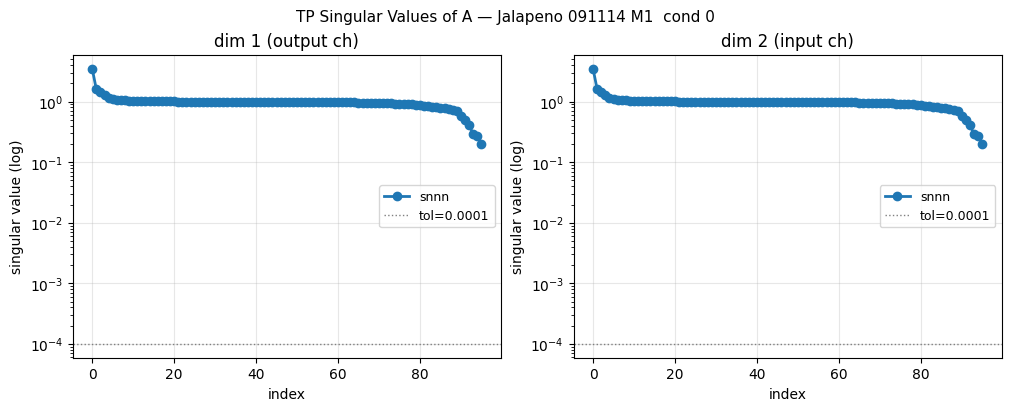

In [ ]:
fig_sv, axes_sv = plt.subplots(1, 2, figsize=(10, 4), constrained_layout=True)
fig_sv.suptitle(f"TP Singular Values of A — {monkey} {date} {site}  cond {c_fit}", fontsize=11)

for ax, dim_idx, dlabel in zip(axes_sv, [0, 1],
                                ["dim 1 (output ch)", "dim 2 (input ch)"]):
    for ht, (_, Uco, sv) in tp_results.items():
        if sv[dim_idx] is not None:
            ax.semilogy(sv[dim_idx], "o-", linewidth=2, label=ht)
    ax.axhline(hosvd_tol, color="gray", linestyle=":", linewidth=1,
               label=f"tol={hosvd_tol}")
    ax.set_title(dlabel)
    ax.set_xlabel("index")
    ax.set_ylabel("singular value (log)")
    ax.legend(fontsize=9)
    ax.grid(True, alpha=0.3)

path = out_dir / f"tp_sv_{tag}.png"
fig_sv.savefig(path, dpi=150)
print(f"Saved → {path}")
plt.show()

## 6 — Plot: Vertex activations on test trials

C:\Users\aditya\AppData\Local\Temp\ipykernel_14772\516824120.py:71: UserWarning: constrained_layout not applied because axes sizes collapsed to zero.  Try making figure larger or Axes decorations smaller.
  fig_act.savefig(path_act, dpi=150)


Saved vertex activations dim0 → C:\Users\aditya\Documents\projects\TPModel\tp_python\plots\tp_vertex_test_Jalapeno_091114_M1_cond0_dim0.png


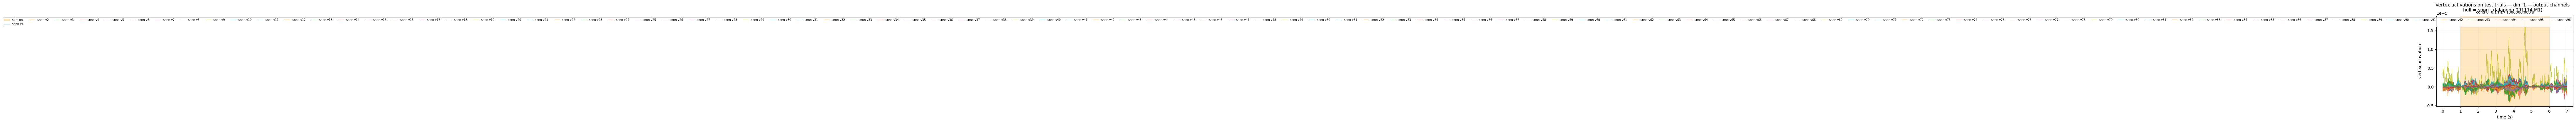

Saved vertex activations dim1 → C:\Users\aditya\Documents\projects\TPModel\tp_python\plots\tp_vertex_test_Jalapeno_091114_M1_cond0_dim1.png


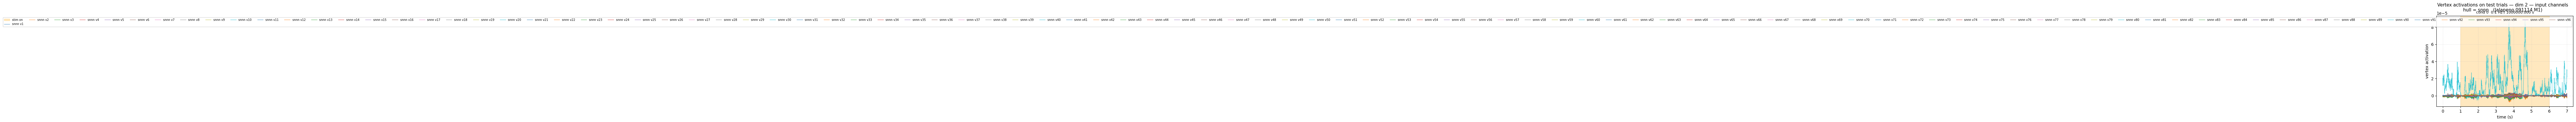

In [ ]:
ht_style = {"snnn": "-"}
cmap_v   = plt.cm.tab10
sample_conditions = FIT_CONDITIONS

for dim_key, act_key, dim_label in [
    ("r0", "act_r", "dim 1 — output channels"),
    ("r1", "act_s", "dim 2 — input channels"),
]:
    n_panels = len(sample_conditions)
    fig_act, axes_act = plt.subplots(
        1, n_panels, figsize=(6 * n_panels, 4),
        sharey=True, constrained_layout=True, squeeze=False,
    )
    axes_act = axes_act[0]
    fig_act.suptitle(
        f"Vertex activations on test trials — {dim_label}\n"
        f"hull = snnn   ({monkey} {date} {site})",
        fontsize=11,
    )

    for col, c_idx in enumerate(sample_conditions):
        cond       = conditions[c_idx]
        test_trial = test_idx[0]
        y_test = cond["ecog"][test_trial].T     # (n_samples, n_channels)
        u_test = inputs[c_idx][test_trial]      # (n_samples,)
        t_s    = np.arange(n_samples) / fs

        ax = axes_act[col]
        ax.set_title(
            f"cond {c_idx}  {cond['stim_freq']:.1f} Hz / "
            f"{cond['stim_pw']*pw_unit_scale:.3f} s",
            fontsize=9,
        )

        stim_on = u_test.astype(bool)
        if stim_on.any():
            ax.fill_between(t_s, 0, 1, where=stim_on,
                            transform=ax.get_xaxis_transform(),
                            color="orange", alpha=0.25, label="stim on")

        max_verts = 0
        for ht, (Sco, Uco, sv) in tp_results.items():
            W0, W1 = Uco[0], Uco[1]
            if W0 is None or W1 is None:
                continue

            alpha   = y_test @ W0
            beta    = y_test @ W1
            contrib = np.einsum("rs,tr,ts->rst", Sco, alpha, beta)
            act_r   = contrib.sum(axis=1).T
            act_s   = contrib.sum(axis=0).T

            act = act_r if act_key == "act_r" else act_s
            n_v = act.shape[1]
            max_verts = max(max_verts, n_v)
            ls  = ht_style.get(ht, "-")

            for v in range(n_v):
                label = f"{ht} v{v+1}" if col == 0 else None
                ax.plot(t_s, act[:, v], linestyle=ls, linewidth=0.8,
                        color=cmap_v(v % 10), label=label, alpha=0.85)

        ax.set_xlabel("time (s)")
        ax.grid(True, alpha=0.2)
        if col == 0:
            ax.set_ylabel("vertex activation")
            ax.legend(fontsize=7, ncol=max(1, max_verts))

    dim_tag = "0" if act_key == "act_r" else "1"
    path_act = out_dir / f"tp_vertex_test_{tag}_dim{dim_tag}.png"
    fig_act.savefig(path_act, dpi=150)
    print(f"Saved vertex activations dim{dim_tag} → {path_act}")
    plt.show()